In [1]:
import numpy as np
import pandas as pd 

df = pd.read_csv("Features.csv")

In [2]:
df.shape

(57303, 24)

In [3]:

import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Target and selected features
target = "construction_cost"

selected_features = [
    "district_name",
    "block_tehsil_name",
    "village_name",
    "latitude",
    "longitude",
    "scheme_type",
    "ownership",
    "total_owners_holding",
    "social_status",
    "gender",
    "scheme_depth",
    "scheme_diameter",
    "nearest_scheme_distance",
    "water_distribution_method",
    "lifting_device_type",
    "energy_source",
    "horse_power_of_lifting_device",
    "located_in_command_area",
    "only_recharge_ground_water",
    "culturable_command_area",
    "drinking_water_purpose",
    "well_type",
    "finance_source"
]

# Prepare data
data = df[selected_features + [target]].copy()
data = data.drop_duplicates()
data = data.dropna(subset=[target])
data = data[data[target] >= 0]

X = data[selected_features].copy()
y = data[target].astype(float)

# Identify categorical features
cat_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Handle missing values
for col in cat_features:
    X[col] = X[col].fillna("Unknown").astype(str)

numeric_features = [
    col for col in X.columns if col not in cat_features
]

for col in numeric_features:
    X[col] = X[col].replace([np.inf, -np.inf], np.nan)
    X[col] = X[col].fillna(X[col].median())

# Split: 64% training, 16% validation, 20% testing
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=0.20,
    random_state=42
)

# Create model
model = CatBoostRegressor(
    iterations=1500,
    depth=8,
    learning_rate=0.05,
    loss_function="MAE",
    eval_metric="MAE",
    random_seed=42,
    early_stopping_rounds=150,
    verbose=100,
    allow_writing_files=False
)

# Train
model.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_val, y_val),
    use_best_model=True
)

# Evaluate on the untouched test set
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n--- FINAL TEST RESULTS ---")
print(f"Training rows:   {len(X_train):,}")
print(f"Validation rows: {len(X_val):,}")
print(f"Testing rows:    {len(X_test):,}")
print(f"Best iteration:  {model.best_iteration_}")
print(f"MAE:             ₹{mae:,.2f}")
print(f"RMSE:            ₹{rmse:,.2f}")
print(f"R² score:        {r2:.4f}")


0:	learn: 147117.7821185	test: 136706.2946462	best: 136706.2946462 (0)	total: 262ms	remaining: 6m 32s
100:	learn: 90157.6219869	test: 80478.8103749	best: 80478.8103749 (100)	total: 11.1s	remaining: 2m 33s
200:	learn: 77868.8018299	test: 69328.9191349	best: 69328.9191349 (200)	total: 21.6s	remaining: 2m 19s
300:	learn: 70599.3559002	test: 63548.1845428	best: 63548.1845428 (300)	total: 31.7s	remaining: 2m 6s
400:	learn: 67282.0537328	test: 61553.0966107	best: 61553.0966107 (400)	total: 42.4s	remaining: 1m 56s
500:	learn: 63901.6293498	test: 59971.3325778	best: 59971.3325778 (500)	total: 52.8s	remaining: 1m 45s
600:	learn: 61011.7164240	test: 58448.2458196	best: 58448.2458196 (600)	total: 1m 3s	remaining: 1m 34s
700:	learn: 58917.9935415	test: 57506.5226558	best: 57506.5226558 (700)	total: 1m 13s	remaining: 1m 23s
800:	learn: 57612.0897288	test: 57094.8238278	best: 57079.0267034 (797)	total: 1m 23s	remaining: 1m 13s
900:	learn: 55931.5224440	test: 56277.5738498	best: 56277.5738498 (900)	t

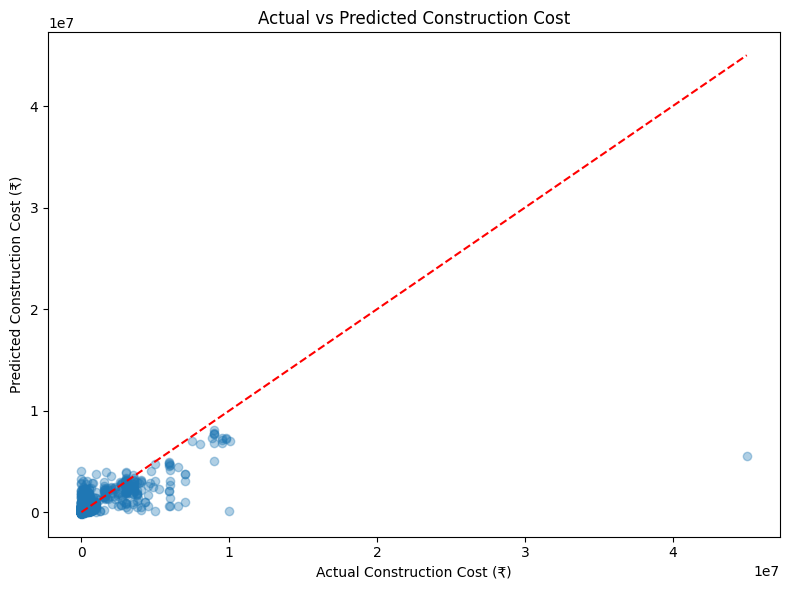

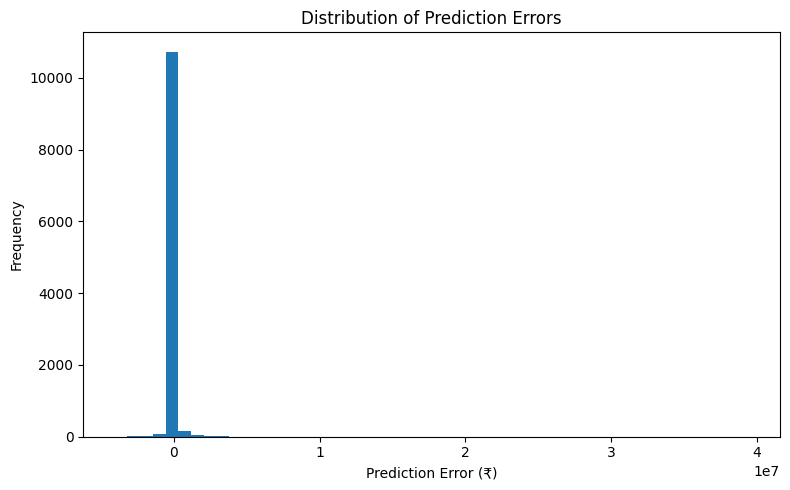

In [4]:

import matplotlib.pyplot as plt

# Actual vs predicted costs
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.35)
plt.plot(
    [0, max(y_test.max(), y_pred.max())],
    [0, max(y_test.max(), y_pred.max())],
    "r--"
)
plt.xlabel("Actual Construction Cost (₹)")
plt.ylabel("Predicted Construction Cost (₹)")
plt.title("Actual vs Predicted Construction Cost")
plt.tight_layout()
plt.show()

# Prediction error distribution
errors = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.hist(errors, bins=50)
plt.xlabel("Prediction Error (₹)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")
plt.tight_layout()
plt.show()


In [5]:

new_scheme = pd.DataFrame([{
    "district_name": "Goalpara",
    "block_tehsil_name": "Kuchdhowa",
    "village_name": "Siluk Pt-Ii",
    "latitude": 25.95699,
    "longitude": 90.79973,
    "scheme_type": "Tube well",
    "ownership": "Govt. Owned",
    "total_owners_holding": 0,
    "social_status": "Unknown",
    "gender": "Unknown",
    "scheme_depth": 45,
    "scheme_diameter": 150,
    "nearest_scheme_distance": 20,
    "water_distribution_method": "Other",
    "lifting_device_type": "Others",
    "energy_source": "Solar",
    "horse_power_of_lifting_device": 3,
    "located_in_command_area": "No",
    "only_recharge_ground_water": "No",
    "culturable_command_area": 4,
    "drinking_water_purpose": "No",
    "well_type": "Tubewell: Medium Tube well",
    "finance_source": "Government fund"
}])

# Match training column order
new_scheme = new_scheme[selected_features]

for col in cat_features:
    new_scheme[col] = new_scheme[col].fillna("Unknown").astype(str)

for col in numeric_features:
    new_scheme[col] = pd.to_numeric(
        new_scheme[col], errors="coerce"
    )
    new_scheme[col] = new_scheme[col].replace(
        [np.inf, -np.inf], np.nan
    )
    new_scheme[col] = new_scheme[col].fillna(X[col].median())

predicted_cost = model.predict(new_scheme)[0]

print(f"Predicted construction cost: ₹{predicted_cost:,.2f}")


Predicted construction cost: ₹422,840.21
